In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns  

In [2]:
df=pd.read_csv("HR_Attrition_Raw.csv")

In [3]:
df = df[df['EmployeeID'].notna()]
df["EmployeeID"].isnull().sum()

np.int64(0)

In [4]:
df["Age"] = df["Age"].replace({
    -5: 5,
    48.33094995: 48,
    999: 99
})

In [5]:
df["Age"]=df["Age"].fillna(df["Age"].mean())

In [6]:
df["Department"]=df["Department"].fillna("other")

In [7]:
df["Department"]=df["Department"].replace({"hr":"HR",
                                           "SALES":"Sales"})



In [8]:
df["SalaryBand"]=df["SalaryBand"].replace({"low":"Low",
                                           "HIGH":"High",
                                           "MED":"Medium"})


In [9]:
df["SalaryBand"]=df["SalaryBand"].fillna("other")

In [10]:
df["JobRole"].value_counts()

JobRole
MANAGER           117
Engineer          110
Associate         102
Senior Analyst    101
Lead              100
analyst           100
Director           96
Analyst            93
Manager            83
Name: count, dtype: int64

In [11]:
df["JobRole"]=df["JobRole"].replace({"MANAGER":"Manager",
                                     "MED":"Medium"}
)



In [12]:
df["JobRole"]=df["JobRole"].fillna("other")

In [13]:
df["Gender"] = df["Gender"].str.strip()

df["Gender"] = df["Gender"].replace({
    "male": "Male",
    "M": "Male",
    "F": "Female",
    "FEMALE": "Female",
    "other" : "Other"
})

In [14]:
df["Gender"]=df["Gender"].fillna("other")

In [15]:
df["YearsAtCompany"] = df["YearsAtCompany"].replace('Unknown', np.nan)
df["YearsAtCompany"] = df["YearsAtCompany"].astype(float)
df["YearsAtCompany"]=df["YearsAtCompany"].fillna(df["YearsAtCompany"].mean())

In [16]:
df["PerformanceScore"]=df["PerformanceScore"].fillna(df["PerformanceScore"].mean())

In [17]:
df["MonthlyIncome"]=df["MonthlyIncome"].replace("#ERROR",np.nan)

In [18]:
df["MonthlyIncome"]=df["MonthlyIncome"].replace("-1000",1000)

In [19]:
df["Attrition"]=df["Attrition"].replace({"1":"Yes",
                                         "y":"Yes",
                                         "YES":"Yes",
                                         "no":"No",
                                         "0":"No",
                                         np.nan:"Yes"
                                         })


In [20]:
df["Attrition"].value_counts()

Attrition
No     726
Yes    274
Name: count, dtype: int64


==  CATEGORICAL VARIABLES  ==


-- Department --
Department
HR             194
Sales          187
Engineering    121
IT             105
Operations     102
Finance        100
Marketing       96
other           95
Name: count, dtype: int64


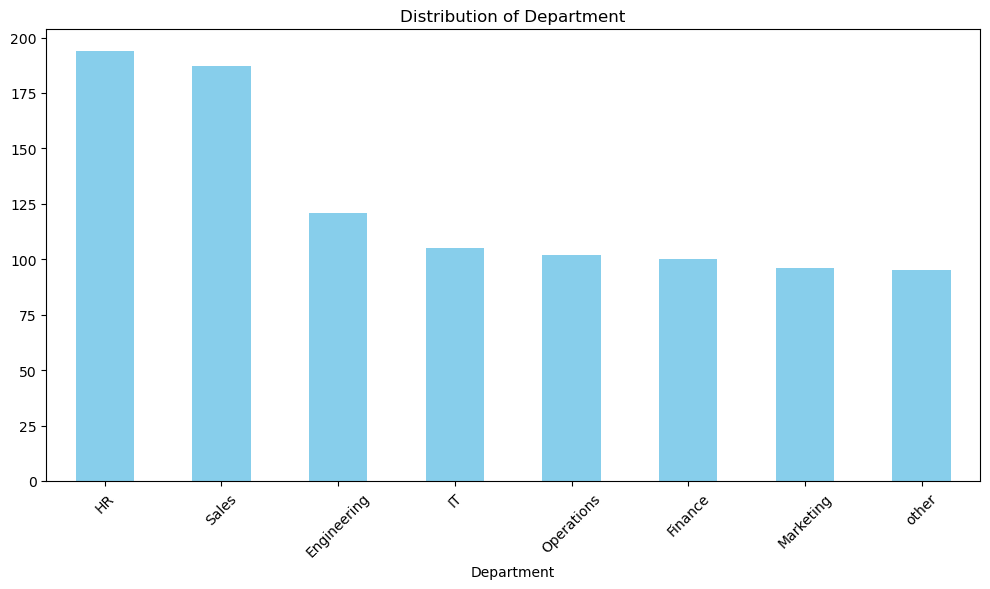


-- SalaryBand --
SalaryBand
High         204
Low          203
Medium       197
other        108
Band-B       107
Very High     92
Band-A        89
Name: count, dtype: int64


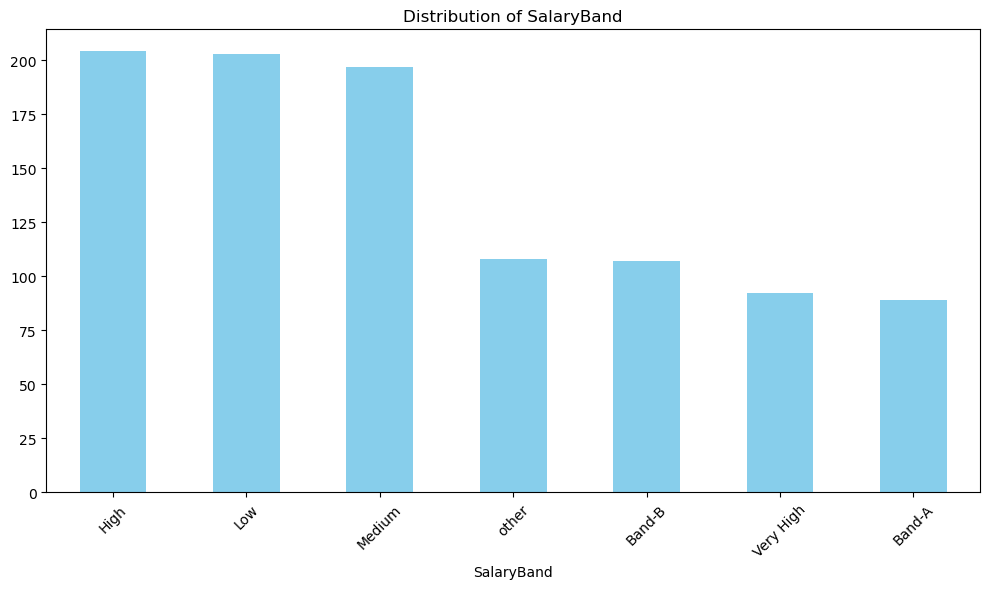


-- JobRole --
JobRole
Manager           200
Engineer          110
Associate         102
Senior Analyst    101
Lead              100
analyst           100
other              98
Director           96
Analyst            93
Name: count, dtype: int64


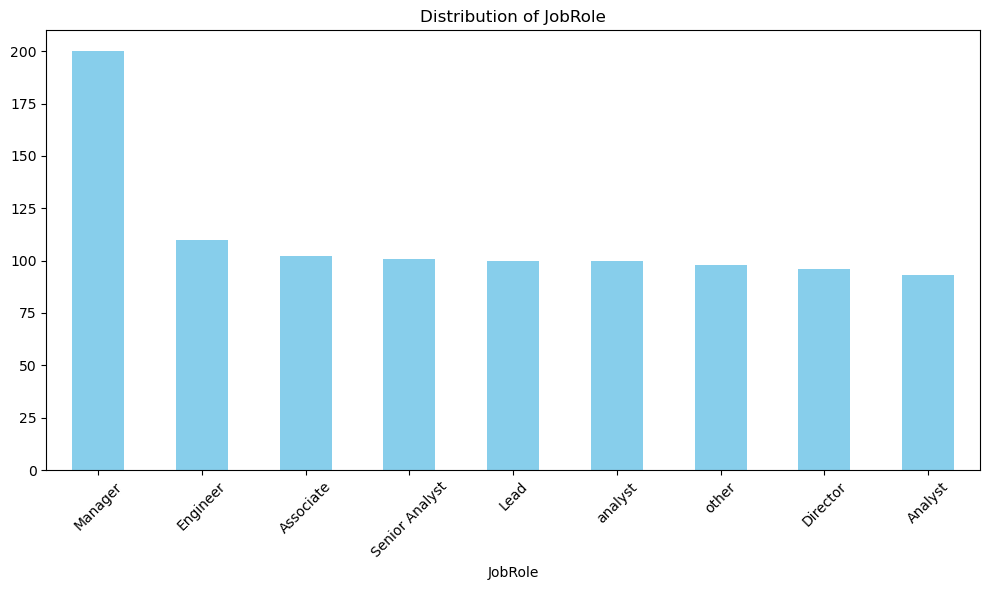


-- Gender --
Gender
Male      412
Female    396
Other     104
other      88
Name: count, dtype: int64


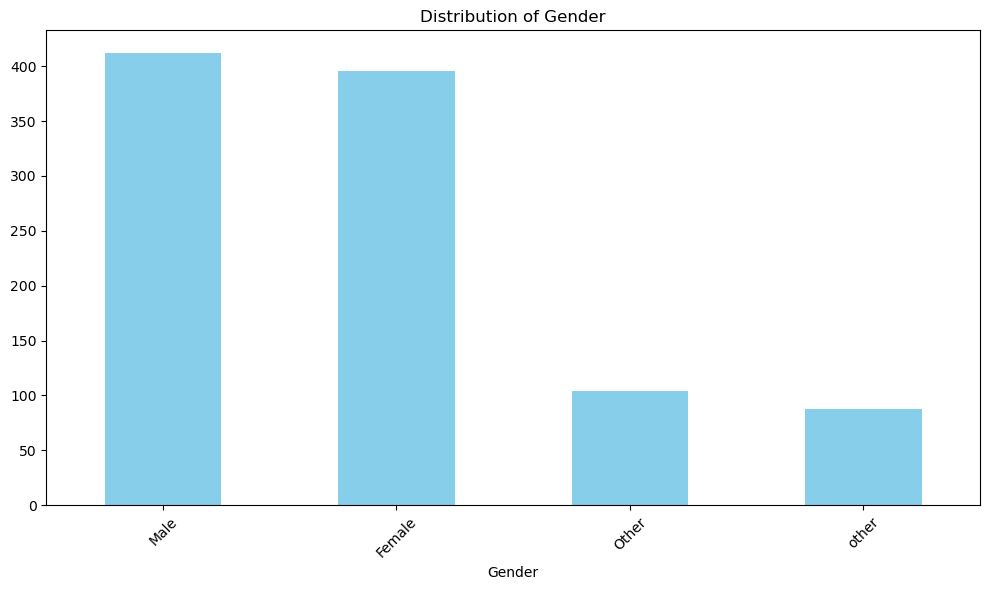


-- Attrition --
Attrition
No     726
Yes    274
Name: count, dtype: int64


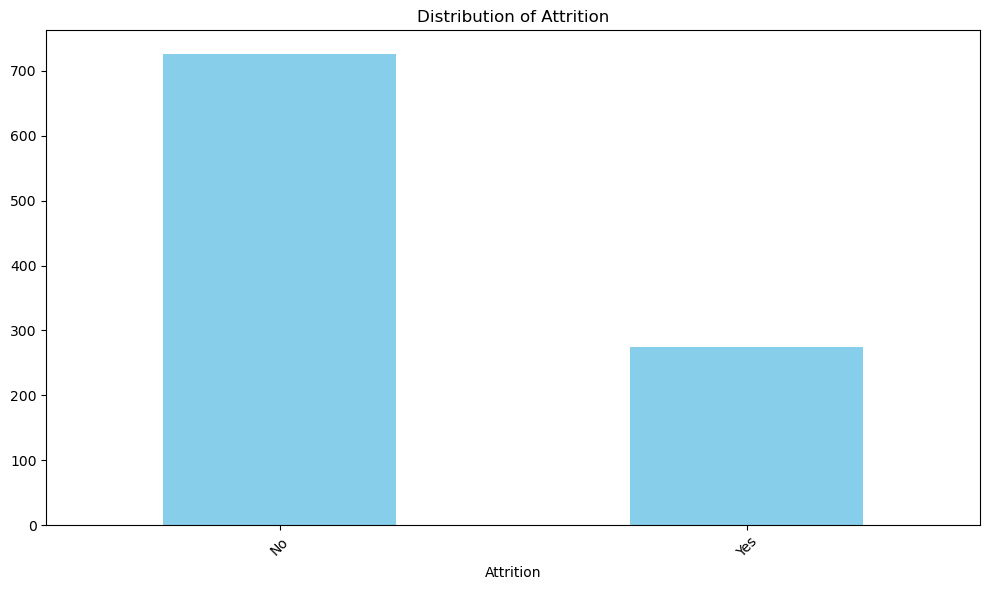

In [ ]:
print("\n==  CATEGORICAL VARIABLES  ==\n")
categorical_cols = ["Department","SalaryBand", "JobRole", "Gender", "Attrition"]

for col in categorical_cols:
    print(f"\n-- {col} --")
    print(df[col].value_counts())


    #VISUALIZATION

    plt.figure(figsize=(10,6))
    df[col].value_counts().plot(kind="bar",color="skyblue")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()





==  NUMERICAL VARIABLES  ==


--- Age ---
Mean: 41.11
Median: 41.11
Std Dev: 12.69
Min: 5.00
Max: 99.00


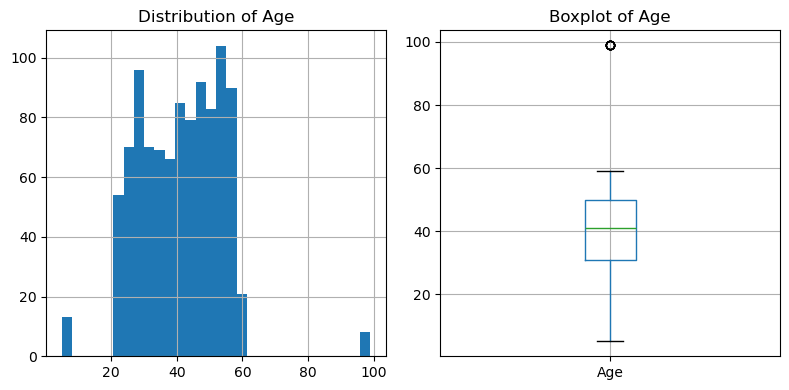


--- YearsAtCompany ---
Mean: 17.44
Median: 17.44
Std Dev: 9.85
Min: -1.00
Max: 35.00


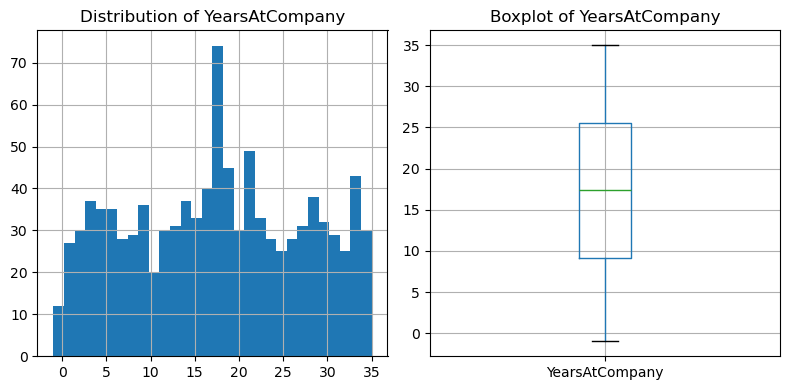


--- PerformanceScore ---
Mean: 4.26
Median: 3.10
Std Dev: 10.95
Min: -1.00
Max: 99.00


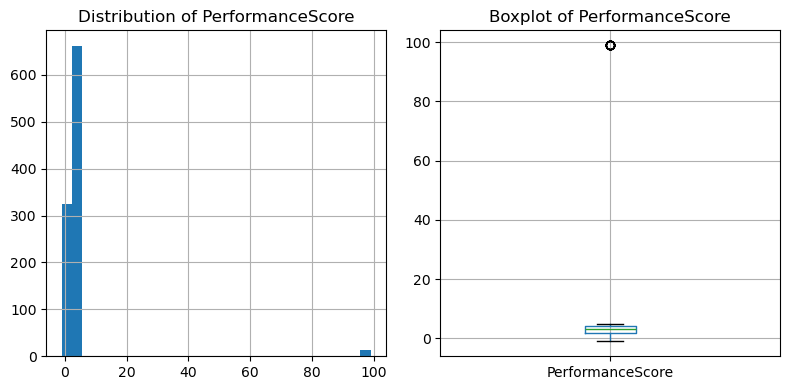


--- MonthlyIncome ---
Mean: 83763.69
Median: 86346.16
Std Dev: 38747.83
Min: 0.00
Max: 149940.71


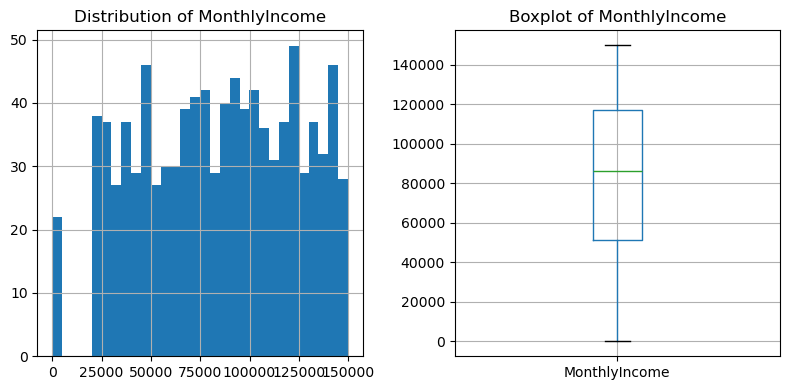

In [ ]:
print("\n==  NUMERICAL VARIABLES  ==\n")

numerical_cols = [
    "Age","YearsAtCompany","PerformanceScore","MonthlyIncome"
    
]

for col in numerical_cols:

    df[col] = pd.to_numeric(df[col], errors='coerce')

    print(f"\n--- {col} ---")
    print(f"Mean: {df[col].mean():.2f}")
    print(f"Median: {df[col].median():.2f}")
    print(f"Std Dev: {df[col].std():.2f}")
    print(f"Min: {df[col].min():.2f}")
    print(f"Max: {df[col].max():.2f}")

    plt.figure(figsize=(8,4))

    plt.subplot(1,2,1)
    df[col].hist(bins=30)
    plt.title(f"Distribution of {col}")

    plt.subplot(1,2,2)
    df.boxplot(column=col)
    plt.title(f"Boxplot of {col}")

    plt.tight_layout()
    plt.show()

             MonthlyIncome        Age  Employee Count
Department                                           
Engineering   86115.674661  40.148760             121
Finance       75431.572917  41.450000             100
HR            85116.596044  40.503944             194
IT            82825.747800  41.508926             105
Marketing     88546.901368  42.001138              96
Operations    85554.067959  41.229776             102
Sales         82118.940552  40.980947             187
other         84165.273936  41.990624              95


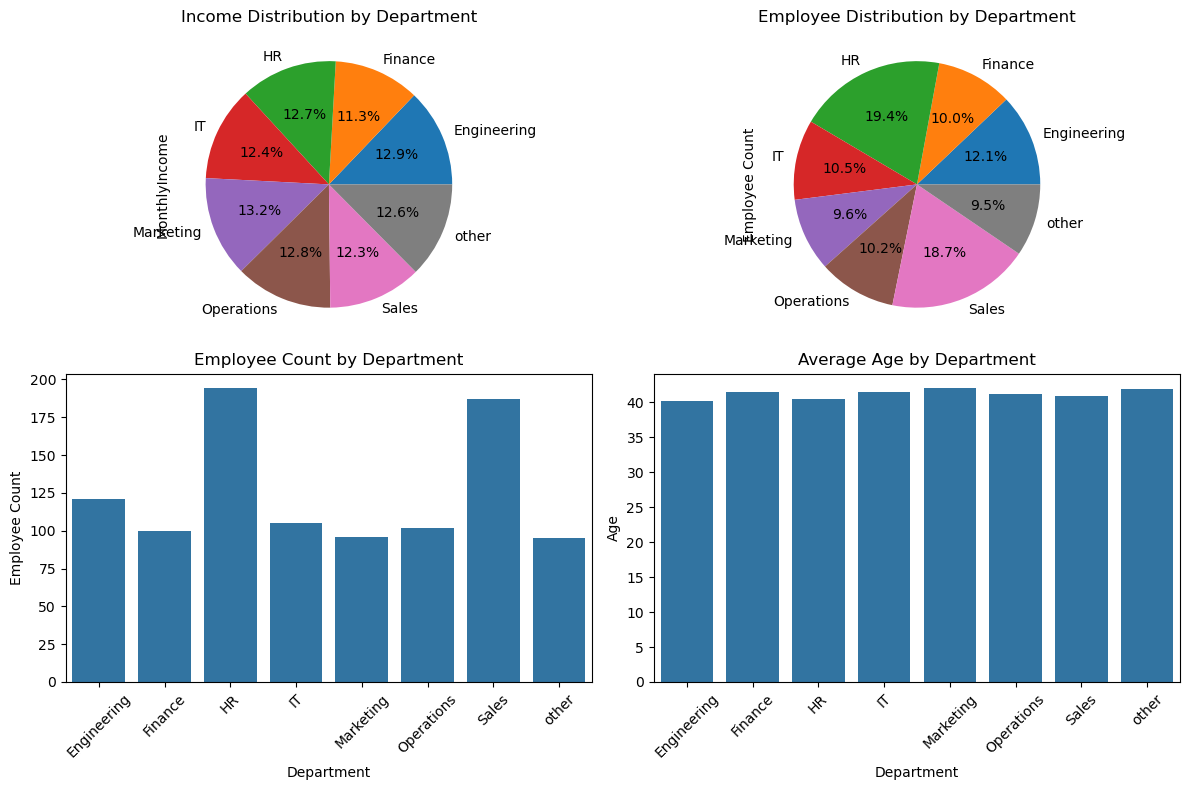

In [23]:
department_performance = df.groupby('Department').agg({
    'MonthlyIncome': 'mean',
    'Age': 'mean',
    'EmployeeID': 'count'
}).rename(columns={
    'EmployeeID': 'Employee Count'
})

print(department_performance)

plt.figure(figsize=(12,8))

# Average Monthly Income
plt.subplot(2,2,1)
department_performance['MonthlyIncome'].plot(
    kind='pie',
    autopct='%1.1f%%'
)
plt.title('Income Distribution by Department')

# Employee Count
plt.subplot(2,2,2)
department_performance['Employee Count'].plot(
    kind='pie',
    autopct='%1.1f%%'
)
plt.title('Employee Distribution by Department')

# Employee Count Bar Chart
plt.subplot(2,2,3)
sns.barplot(
    x=department_performance.index,
    y=department_performance['Employee Count']
)
plt.title('Employee Count by Department')
plt.xticks(rotation=45)

# Average Age
plt.subplot(2,2,4)
sns.barplot(
    x=department_performance.index,
    y=department_performance['Age']
)
plt.title('Average Age by Department')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

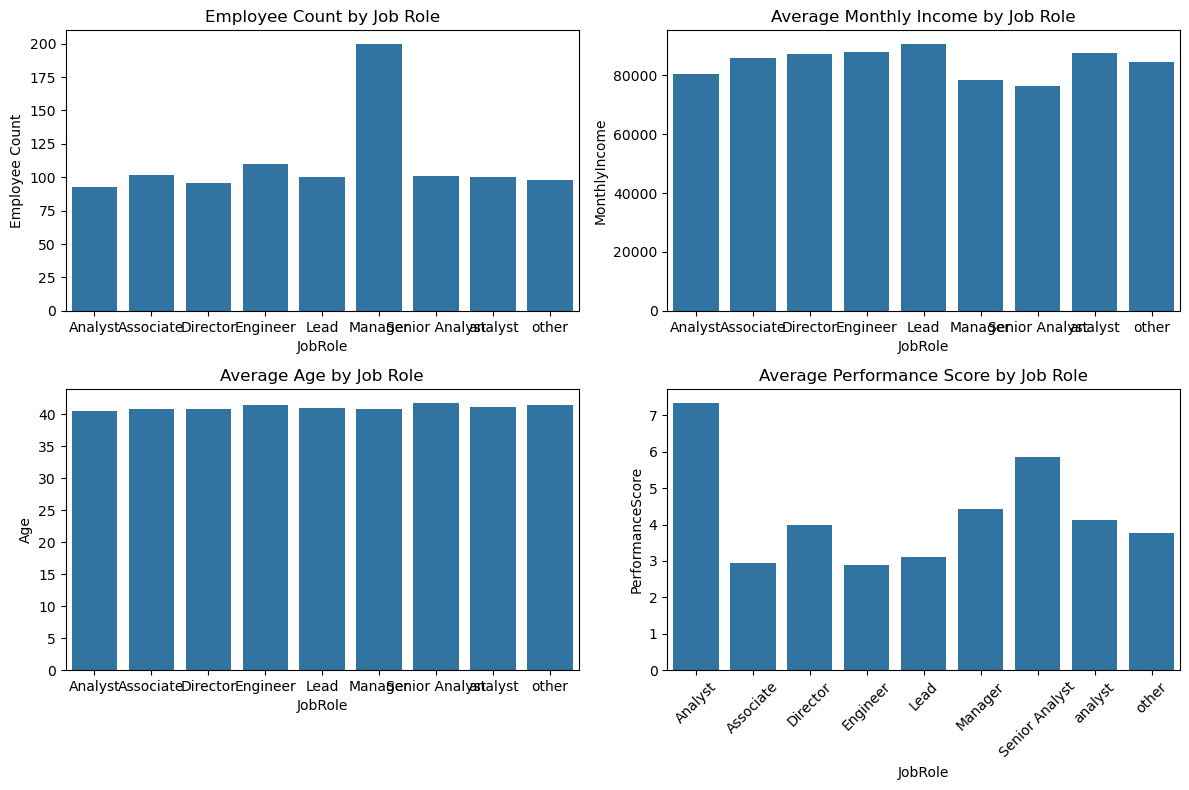

In [24]:
jobrole_analysis = df.groupby("JobRole").agg({
    "MonthlyIncome": "mean",
    "Age": "mean",
    "PerformanceScore": "mean",
    "EmployeeID": "count"
}).rename(columns={"EmployeeID": "Employee Count"})


plt.figure(figsize=(12, 8))

# Employee Count
plt.subplot(2, 2, 1)
sns.barplot(
    x=jobrole_analysis.index,
    y=jobrole_analysis['Employee Count']
)
plt.title('Employee Count by Job Role')

# Average Monthly Income
plt.subplot(2, 2, 2)
sns.barplot(
    x=jobrole_analysis.index,
    y=jobrole_analysis['MonthlyIncome']
)
plt.title('Average Monthly Income by Job Role')

# Average Age
plt.subplot(2, 2, 3)
sns.barplot(
    x=jobrole_analysis.index,
    y=jobrole_analysis['Age']
)
plt.title('Average Age by Job Role')

# Average Performance Score
plt.subplot(2, 2, 4)
sns.barplot(
    x=jobrole_analysis.index,
    y=jobrole_analysis['PerformanceScore']
)
plt.title('Average Performance Score by Job Role')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

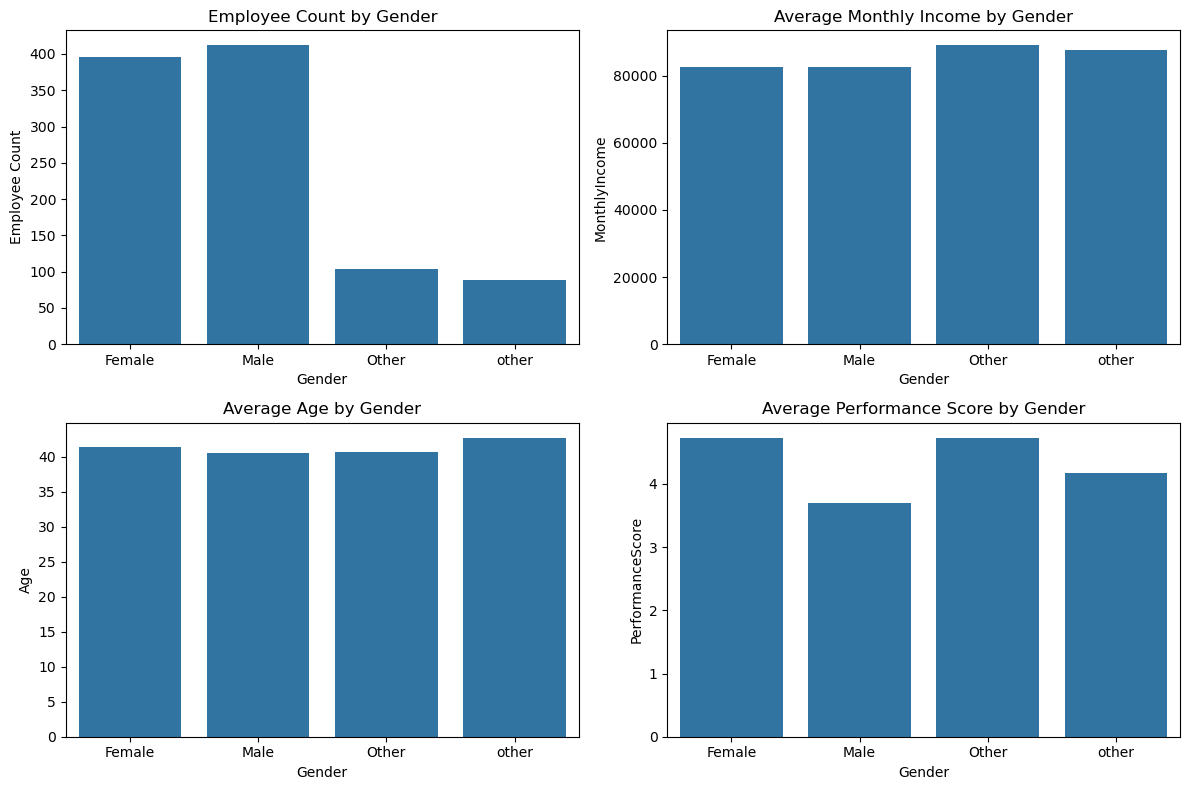

In [25]:
gender_analysis = df.groupby("Gender").agg({
    "MonthlyIncome": "mean",
    "Age": "mean",
    "PerformanceScore": "mean",
    "EmployeeID": "count"
}).rename(columns={"EmployeeID": "Employee Count"})


plt.figure(figsize=(12, 8))

# Employee Count
plt.subplot(2, 2, 1)
sns.barplot(
    x=gender_analysis.index,
    y=gender_analysis['Employee Count']
)
plt.title('Employee Count by Gender')

# Average Monthly Income
plt.subplot(2, 2, 2)
sns.barplot(
    x=gender_analysis.index,
    y=gender_analysis['MonthlyIncome']
)
plt.title('Average Monthly Income by Gender')

# Average Age
plt.subplot(2, 2, 3)
sns.barplot(
    x=gender_analysis.index,
    y=gender_analysis['Age']
)
plt.title('Average Age by Gender')

# Average Performance Score
plt.subplot(2, 2, 4)
sns.barplot(
    x=gender_analysis.index,
    y=gender_analysis['PerformanceScore']
)
plt.title('Average Performance Score by Gender')

plt.tight_layout()
plt.show()